# Figure 4 - Figure Code

Fitting Full Model...
Full Model Fit Complete.
Full Model Marginal R²: 0.1183
Starting Leave-One-Out analysis on 10 predictors...


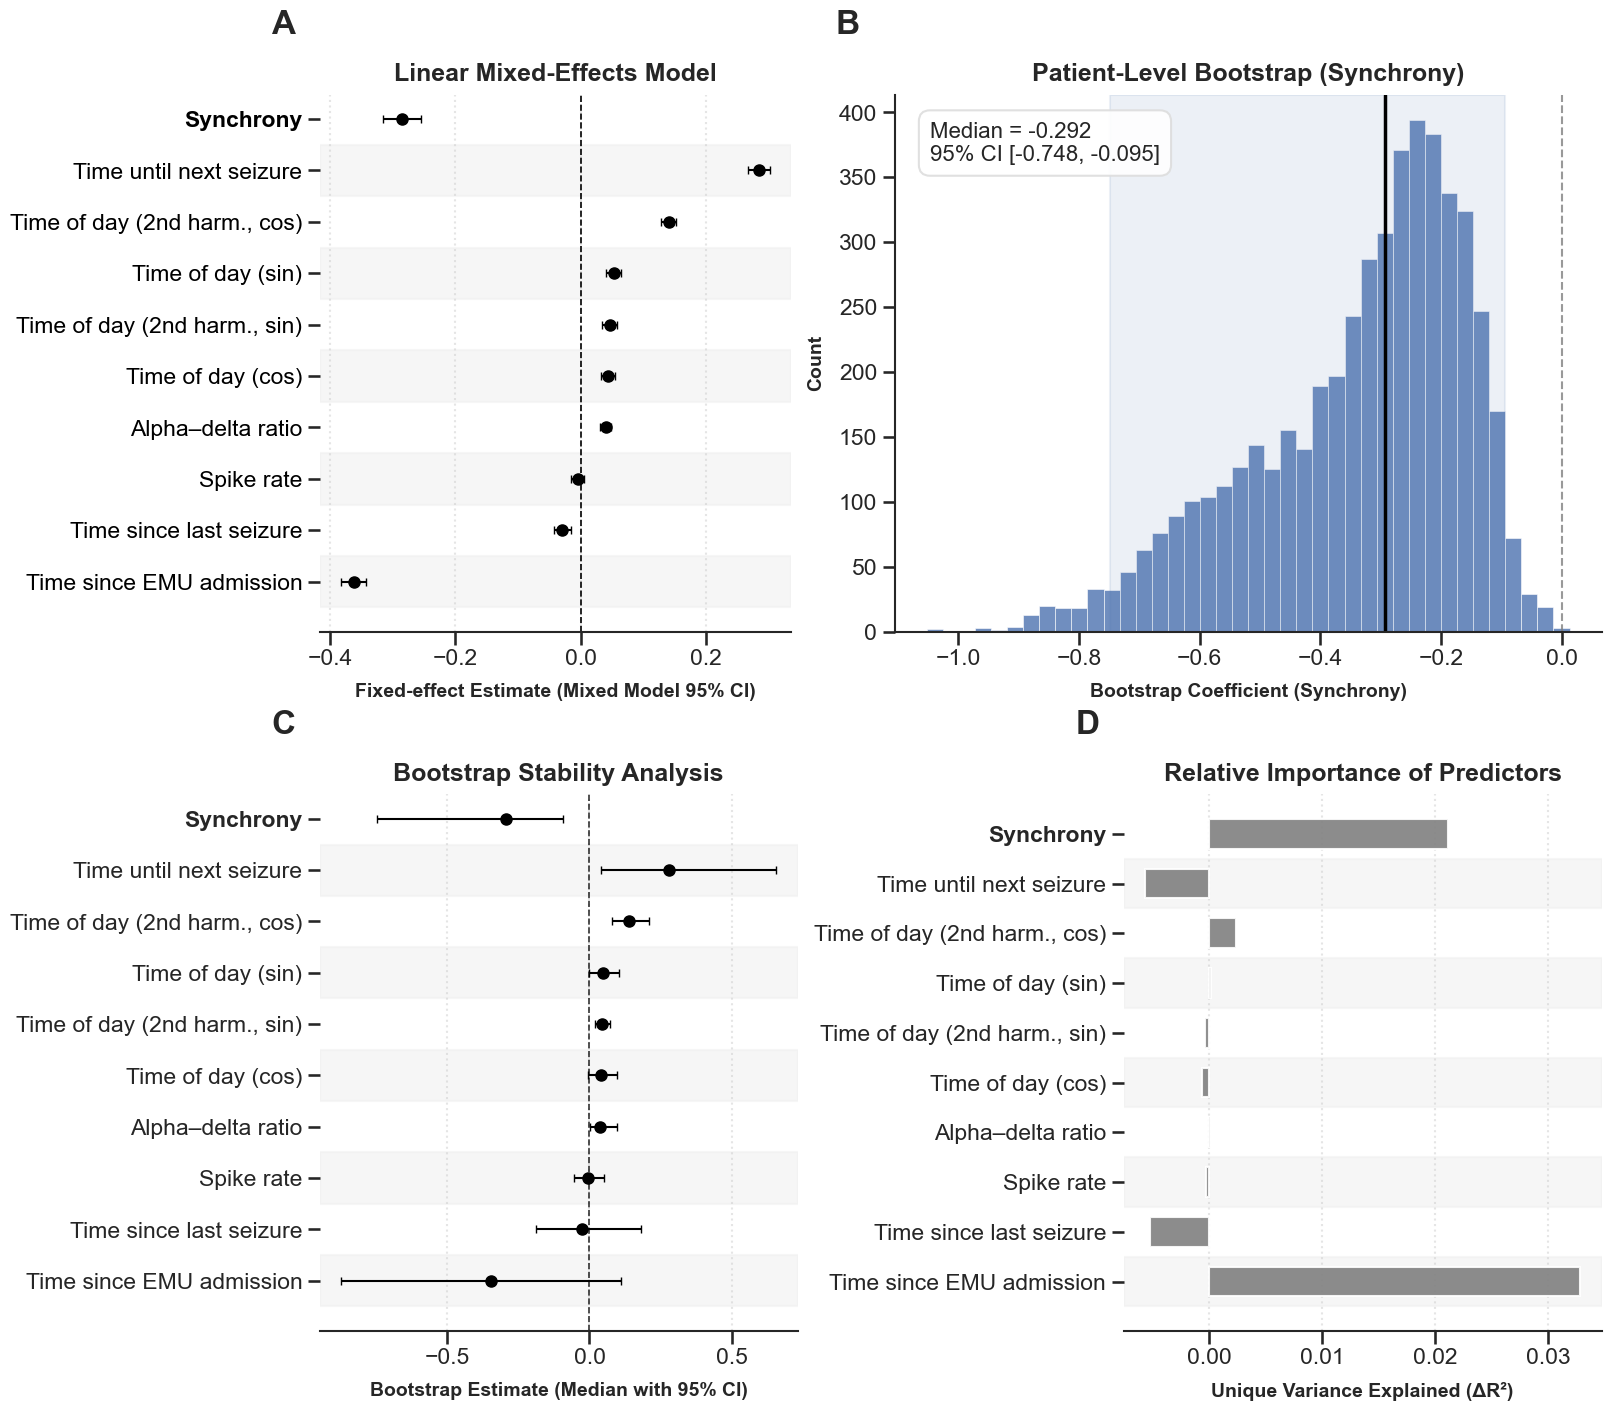

In [1]:
import os
import numpy as np
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler

# --- 1. CONFIGURATION & DATA LOADING ---

DATA_PATH = "../../cnt-data/"
TABLES_PATH = os.path.join(DATA_PATH, "revised_tables_step_4")

sns.set_style("whitegrid")
sns.set_theme(style="ticks", context="talk")

def get_patient_hup_ids(directory):
    if not os.path.exists(directory):
        # Fallback for testing/script generation purposes if path doesn't exist
        print(f"Warning: Path {directory} not found.")
        return []
    files = os.listdir(directory)
    patient_hup_ids = [
        int(f.split("_")[1].split(".")[0]) for f in files if f.startswith("HUP_")
    ]
    return patient_hup_ids

completed_hup_ids = get_patient_hup_ids(TABLES_PATH)
completed_hup_ids.sort()

dfs = []
# Columns required for analysis
columns_to_keep = [
    "emu_minute", "synchrony_broadband", "med_sum_no_lorazepam_raw",
    "time_since_last_seizure", "time_until_next_seizure", "ad_ratio",
    "tod_sin", "tod_cos", "tod_sin2", "tod_cos2", "spike_rate", "patient_hup_id",
]

# Load Data
for patient_hup_id in completed_hup_ids:
    patient_features_df = pd.read_csv(
        os.path.join(TABLES_PATH, f"HUP_{patient_hup_id}.csv"),
        low_memory=False
    )
    patient_features_df["patient_hup_id"] = patient_hup_id
    existing_columns = [c for c in columns_to_keep if c in patient_features_df.columns]
    patient_features_df = patient_features_df[existing_columns]
    dfs.append(patient_features_df)

if dfs:
    all_data = pd.concat(dfs).reset_index(drop=True)
else:
    raise ValueError("No data loaded. Check paths.")

# Drop NaNs
all_data = all_data.dropna(subset=columns_to_keep).reset_index(drop=True)

# Scale Variables
scaler = StandardScaler()
cols_to_scale = [
    "synchrony_broadband", "time_since_last_seizure", "time_until_next_seizure",
    "emu_minute", "ad_ratio", "spike_rate",
]
all_data[cols_to_scale] = scaler.fit_transform(all_data[cols_to_scale])

# --- 2. DEFINE NAKAGAWA R2 FUNCTION ---

def get_nakagawa_r2(model_result):
    """
    Calculates Marginal and Conditional R^2 using the Nakagawa & Schielzeth method.
    """
    # A. Variance of Fixed Effects (σ²_f)
    pred_fixed = np.dot(model_result.model.exog, model_result.fe_params)
    var_fixed = np.var(pred_fixed)

    # B. Variance of Random Effects (σ²_r)
    # For a Random Intercept model, taking the top-left value of covariance matrix
    var_random = model_result.cov_re.iloc[0, 0]

    # C. Variance of Residuals (σ²_ε)
    var_resid = model_result.scale

    # D. Calculate R2
    total_var = var_fixed + var_random + var_resid
    
    # Marginal R2: Variance explained by Fixed Effects only
    r2_marginal = var_fixed / total_var
    
    # Conditional R2: Variance explained by Fixed + Random Effects
    r2_conditional = (var_fixed + var_random) / total_var

    return {
        "marginal": r2_marginal, 
        "conditional": r2_conditional
    }

# --- 3. FIT FULL MODEL (Panel A Data) ---

outcome_var = "med_sum_no_lorazepam_raw"
predictor_vars = [
    "synchrony_broadband",
    "time_since_last_seizure",
    "time_until_next_seizure",
    "emu_minute",
    "ad_ratio",
    "tod_sin", "tod_cos", "tod_sin2", "tod_cos2",
    "spike_rate",
]

full_formula = outcome_var + " ~ " + " + ".join(predictor_vars)
print("Fitting Full Model...")

base_model = smf.mixedlm(
    full_formula,
    all_data,
    groups=all_data["patient_hup_id"],
)
base_result = base_model.fit(reml=True)
print("Full Model Fit Complete.")

# --- 4. CALCULATE DELTA R2 (Panel D Data) ---

# Calculate R2 for full model
full_r2_stats = get_nakagawa_r2(base_result)
print(f"Full Model Marginal R²: {full_r2_stats['marginal']:.4f}")

partial_r2_rows = []
print(f"Starting Leave-One-Out analysis on {len(predictor_vars)} predictors...")

for var in predictor_vars:
    # Build reduced formula
    reduced_predictors = [v for v in predictor_vars if v != var]
    reduced_formula = outcome_var + " ~ " + " + ".join(reduced_predictors)

    # Fit reduced model
    reduced_model = smf.mixedlm(
        reduced_formula,
        all_data,
        groups=all_data["patient_hup_id"],
    )
    # disp=0 suppresses convergence logs
    try:
        reduced_result = reduced_model.fit(reml=True, disp=0) 
        
        # Calculate Reduced MARGINAL R^2
        reduced_r2_stats = get_nakagawa_r2(reduced_result)
        r2_reduced_marginal = reduced_r2_stats['marginal']
        
        # Delta R2
        delta_r2 = full_r2_stats['marginal'] - r2_reduced_marginal 

        partial_r2_rows.append({
            "term": var,
            "delta_r2": delta_r2, 
        })
    except Exception as e:
        print(f"Error fitting model without {var}: {e}")
        partial_r2_rows.append({"term": var, "delta_r2": 0})

partial_r2_df = pd.DataFrame(partial_r2_rows)

# --- 5. LOAD BOOTSTRAP DATA (Panel B & C Data) ---

input_filename = "bootstrap_results.pkl"
if not os.path.exists(input_filename):
    # Mock data for demonstration if file is missing
    print(f"Warning: '{input_filename}' not found. Using mock data for plotting.")
    boot_coefs = {"synchrony_broadband": np.random.normal(-0.28, 0.05, 5000)}
    # Mock summary df based on base_result
    mock_data = []
    for term, val in base_result.params.items():
        mock_data.append({
            "term": term, 
            "median": val, 
            "ci95_lower": val - 0.1, 
            "ci95_upper": val + 0.1
        })
    bootstrap_summary = pd.DataFrame(mock_data)
else:
    with open(input_filename, "rb") as f:
        saved_data = pickle.load(f)
    boot_coefs = saved_data["boot_coefs"]
    bootstrap_summary = saved_data["bootstrap_summary"]

# --- 6. PLOTTING SETUP ---

label_map = {
    "synchrony_broadband":       "Synchrony",
    "time_since_last_seizure": "Time since last seizure",
    "time_until_next_seizure": "Time until next seizure",
    "emu_minute":               "Time since EMU admission",
    "ad_ratio":                 "Alpha–delta ratio",
    "tod_sin":                  "Time of day (sin)",
    "tod_cos":                  "Time of day (cos)",
    "tod_sin2":                 "Time of day (2nd harm., sin)",
    "tod_cos2":                 "Time of day (2nd harm., cos)",
    "spike_rate":               "Spike rate"
}

# 1. Setup Figure
# We keep constrained_layout=True to handle the labels automatically
fig = plt.figure(figsize=(16, 14), constrained_layout=True)

# 2. Create Outer Grid (2 Rows, 1 Column)
# This simply splits the figure into a Top Half and Bottom Half
gs_outer = fig.add_gridspec(2, 1, height_ratios=[1, 1])

# 3. Create Inner Grids (Decouples the column widths)

# TOP ROW: Panel A vs Panel B
# width_ratios=[1, 1.5] makes Panel B 50% wider than Panel A.
# We give A enough space (1 unit) so labels don't collapse the axis.
gs_top = gs_outer[0].subgridspec(1, 2, width_ratios=[1, 1.5])

# BOTTOM ROW: Panel C vs Panel D
# width_ratios=[1, 1] keeps them equal width.
gs_bot = gs_outer[1].subgridspec(1, 2, width_ratios=[1, 1])

# 4. Create Axes and Map to Dictionary
ax_a = fig.add_subplot(gs_top[0])
ax_b = fig.add_subplot(gs_top[1])
ax_c = fig.add_subplot(gs_bot[0])
ax_d = fig.add_subplot(gs_bot[1])

ax_dict = {'A': ax_a, 'B': ax_b, 'C': ax_c, 'D': ax_d}

# ==========================================
# PANEL A: Mixed Model Fixed Effects
# ==========================================
fe_params = base_result.fe_params            
conf_int = base_result.conf_int(alpha=0.05) 
conf_int.columns = ["ci_lower", "ci_upper"]

coefs = (
    pd.concat([fe_params, conf_int], axis=1)
    .reset_index()
    .rename(columns={"index": "term", 0: "estimate"})
)
coefs = coefs[~coefs["term"].str.startswith("Group")].copy()
coefs = coefs[coefs["term"] != "Intercept"].copy()
coefs["label"] = coefs["term"].map(label_map).fillna(coefs["term"])
coefs["is_synchrony"] = coefs["term"] == "synchrony_broadband"

# Sort
coefs = coefs.sort_values(by=["is_synchrony", "estimate"], ascending=[True, True]).reset_index(drop=True)

# Zebra Stripes A
for i in range(len(coefs)):
    if i % 2 == 0:
        ax_a.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

# Plot Data A
x_err_lower = coefs["estimate"] - coefs["ci_lower"]
x_err_upper = coefs["ci_upper"] - coefs["estimate"]

ax_a.errorbar(
    x=coefs["estimate"],
    y=range(len(coefs)), 
    xerr=[x_err_lower, x_err_upper],
    fmt='o', color='black', ecolor='black',
    capsize=3, markersize=8, linewidth=1.5, zorder=10
)

ax_a.set_yticks(range(len(coefs)))
ax_a.set_yticklabels(coefs["label"], color='black')
for i, row in coefs.iterrows():
    if row["term"] == "synchrony_broadband":
        ax_a.get_yticklabels()[i].set_fontweight('bold')

ax_a.axvline(0, color="black", linestyle="--", linewidth=1.2)
ax_a.set_xlabel("Fixed-effect Estimate (Mixed Model 95% CI)", labelpad=10, fontsize=14, fontweight='bold')
ax_a.set_title("Linear Mixed-Effects Model", fontweight='bold', pad=10)
ax_a.spines['left'].set_visible(False)
ax_a.spines['right'].set_visible(False)
ax_a.spines['top'].set_visible(False)
ax_a.spines['bottom'].set_linewidth(1.5)
ax_a.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL B: Bootstrap Histogram
# ==========================================
sync_term = "synchrony_broadband"

ax_b.set_box_aspect(None) 

if sync_term in boot_coefs:
    sync_coefs = np.array(boot_coefs[sync_term])
    sync_median = np.median(sync_coefs)
    sync_ci95 = np.percentile(sync_coefs, [2.5, 97.5])

    ax_b.hist(sync_coefs, bins=40, 
              edgecolor='white', linewidth=0.5, alpha=0.8)
    ax_b.axvline(0, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
    ax_b.axvline(sync_median, color='black', linestyle="-", linewidth=2.5)
    ax_b.axvspan(sync_ci95[0], sync_ci95[1], color=sns.color_palette()[0], alpha=0.1) # Default color

    ax_b.set_xlabel("Bootstrap Coefficient (Synchrony)", labelpad=10, fontsize=14, fontweight='bold')
    ax_b.set_ylabel("Count", labelpad=10, fontsize=14, fontweight='bold')
    ax_b.set_title("Patient-Level Bootstrap (Synchrony)", fontweight='bold', pad=10)

    stats_text = (
        f"Median = {sync_median:.3f}\n"
        f"95% CI [{sync_ci95[0]:.3f}, {sync_ci95[1]:.3f}]"
    )

    ax_b.text(
        0.05, 0.95, stats_text, 
        transform=ax_b.transAxes, fontsize=16, 
        verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9, edgecolor="#dddddd")
    )

    ax_b.spines['bottom'].set_linewidth(1.5)
    ax_b.spines['left'].set_linewidth(1.5)
    ax_b.spines['top'].set_visible(False)
    ax_b.spines['right'].set_visible(False)
else:
    ax_b.text(0.5, 0.5, "Synchrony data not available", ha='center')

# ==========================================
# PANEL C: Bootstrap Forest Plot
# ==========================================
df_boot = bootstrap_summary.copy()
plot_df_c = pd.merge(coefs[['term', 'label', 'is_synchrony']], df_boot, on='term', how='left')

# Zebra Stripes C
for i in range(len(plot_df_c)):
    if i % 2 == 0:
        ax_c.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

# Plot Data C
x_err_lower_c = plot_df_c['median'] - plot_df_c['ci95_lower']
x_err_upper_c = plot_df_c['ci95_upper'] - plot_df_c['median']

ax_c.errorbar(
    x=plot_df_c['median'],
    y=range(len(plot_df_c)),
    xerr=[x_err_lower_c, x_err_upper_c],
    fmt='o', color='black', ecolor='black',
    capsize=3, markersize=8, linewidth=1.5, zorder=10
)

ax_c.axvline(x=0, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
ax_c.set_yticks(range(len(plot_df_c)))
ax_c.set_yticklabels(plot_df_c['label'])

for i, row in plot_df_c.iterrows():
    if row["is_synchrony"]:
        ax_c.get_yticklabels()[i].set_fontweight('bold')

ax_c.set_xlabel('Bootstrap Estimate (Median with 95% CI)', fontsize=14, fontweight='bold', labelpad=10)
ax_c.set_title("Bootstrap Stability Analysis", fontweight='bold', pad=10)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.spines['left'].set_visible(False)
ax_c.spines['bottom'].set_linewidth(1.5)
ax_c.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL D: Delta R^2 (Unique Variance)
# ==========================================
plot_df_d = pd.merge(coefs[['term', 'label', 'is_synchrony']], partial_r2_df, on='term', how='left')
plot_df_d['delta_r2'] = plot_df_d['delta_r2'].fillna(0)

# Zebra Stripes D
for i in range(len(plot_df_d)):
    if i % 2 == 0:
        ax_d.axhspan(i - 0.5, i + 0.5, color='#f0f0f0', alpha=0.6, zorder=0)

bar_colors = ['gray' for _ in plot_df_d['is_synchrony']]

ax_d.barh(
    y=range(len(plot_df_d)),
    width=plot_df_d['delta_r2'],
    color=bar_colors,
    height=0.6,
    zorder=10,
    alpha=0.9
)

ax_d.set_yticks(range(len(plot_df_d)))
ax_d.set_yticklabels(plot_df_d['label']) 

for i, row in plot_df_d.iterrows():
    if row["is_synchrony"]:
        ax_d.get_yticklabels()[i].set_fontweight('bold')

ax_d.set_xlabel('Unique Variance Explained (ΔR²)', fontsize=14, fontweight='bold', labelpad=10)
ax_d.set_title("Relative Importance of Predictors", fontweight='bold', pad=10)
ax_d.spines['top'].set_visible(False)
ax_d.spines['right'].set_visible(False)
ax_d.spines['left'].set_visible(False)
ax_d.spines['bottom'].set_linewidth(1.5)
ax_d.grid(axis='x', linestyle=':', alpha=0.5)

# ==========================================
# PANEL LABELS
# ==========================================
for label, ax in ax_dict.items():
    ax.text(-0.05, 1.1, label, transform=ax.transAxes, 
            fontsize=24, fontweight='bold', va='bottom', ha='right')

# Save or Show
# plt.savefig("Figure_4_Final.pdf", dpi=300, bbox_inches='tight')
plt.show()